# GetProperties ORCA

Jupyter notebook interface for the automated collection of molecular descriptors and conformer-level post-processing
(i.e., Boltzmann averages, min/max values, etc.) from ORCA files.

For each conformer / structure, this workflow expects:
- `*_SPC.out` for final single-point electronic properties
- `*_SPC.xyz` for geometry-based descriptors
- `*_OPT.out` for frequency / thermochemistry data

Be sure to use the included environment / package structure.

## Imports

In [1]:
# stdlib
import os
import time
import logging
import itertools

from pathlib import Path
from pprint import pprint
from multiprocessing import Pool

# Data wrangling
import numpy as np
import pandas as pd

# Misc
from rdkit import Chem
from natsort import natsorted
from IPython.display import SVG, display

# Custom
from GetPropertiesORCA.goodvibes_functions import get_goodvibes_data
from GetPropertiesORCA.property_functions import get_frontierorbs, get_polarizability, get_dipole, get_volume
from GetPropertiesORCA.property_functions import get_SASA, get_nbo, get_nmr, get_distance, get_angles, get_dihedral
from GetPropertiesORCA.property_functions import get_vbur_scan, get_sterimol_morfeus, get_chelpg, get_hirshfeld
from GetPropertiesORCA.property_functions import get_pyramidalization, get_wall_time, get_plane_angle, get_sterimol_dbstep

from GetPropertiesORCA.utils import convert_files_in_directory
from GetPropertiesORCA.utils import _read_in_mol_sdf_with_xyz_correction
from GetPropertiesORCA.utils import FILE_COLUMN_NAME
from GetPropertiesORCA.utils import draw_3D_mol
from GetPropertiesORCA.utils import configure_logger
from GetPropertiesORCA.utils import split_compound_name
from GetPropertiesORCA.utils import _get_atom_map, mol_to_image

# Initial settings
pd.options.display.max_columns = None
logger = logging.getLogger('notebook')

## ORCA-specific notes

This notebook is the ORCA-only branch of the workflow.

It assumes:
- geometry-based descriptors are taken from sibling `*_SPC.xyz` files
- text/electronic properties are taken from sibling `*_SPC.out` / `*_SPC.OUT` files
- thermochemistry is taken from the matching `*_OPT.out` / `*_OPT.OUT` files
- the final free-energy terms are reconstructed by combining ORCA thermochemistry from `*_OPT.out`
  with the final single-point energy from `*_SPC.out`

## Settings

Point `data_dir` to the directory containing your ORCA files.

Expected file layout for each conformer / structure:
- `name_SPC.out` or `name_SPC.OUT` for final electronic/text properties
- `name_SPC.xyz` for geometry-based descriptors
- `name_OPT.out` or `name_OPT.OUT` for frequency / thermochemistry data

`.mol` files are generated automatically from `*_SPC.xyz` for RDKit atom mapping.


In [2]:
# Point to path of the ORCA .out/.xyz files
data_dir = Path('./')

# Point to path where results and intermediate files are saved
results_dir = Path('./results/')
results_dir.mkdir(exist_ok=True, parents=True)

# Define number of processors to use (set to integer or os.cpu_count())
procs = 4

# Turn on debug printing
debug = False

# Format the logging
configure_logger(debug=debug)

## Convert `.xyz` files to `.mol` files

This section converts the ORCA `.xyz` files to `.mol` files using Open Babel.
The `.mol` files are only used for RDKit substructure matching / atom mapping.

Each `.mol` file must have a sibling `.out`/`.OUT` file with the same stem.

In [3]:
# Convert the xyz files into .mol files for reading in with RDKit
# This function returns the files that failed
failed_files = convert_files_in_directory(directory=data_dir)

# Move and log the failed files
if len(failed_files) != 0:
    logger.warning('Some xyz files do not have corresponding .mol files')
    for f in failed_files:
        logger.warning(f.name)

mol_files = [x for x in data_dir.glob('*.mol')]

logger.info('There are %d files that do not have a corresponding .mol file.', len(failed_files))
logger.info('There are %d .mol files.', len(mol_files))

## Define substructure for featurization
Provide and [SMARTS](https://www.daylight.com/dayhtml/doc/theory/theory.smarts.html) string or SMILES string that defines the substructure to featurize. If you are unfamiliar with SMARTS patterns, begin by copying the SMILES directly from ChemDraw first. If that does not correspond to your desired substructure (e.g., hydrogens are missing), consult the [SMARTS documentation](https://www.daylight.com/dayhtml/doc/theory/theory.smarts.html). You can visualize your
SMARTS query with the [SMARTS PLUS](https://smarts.plus/) webtool.


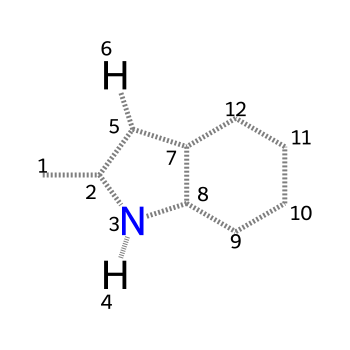

In [4]:
# Define a substructure common to all data files you are looking at
substructure = Chem.MolFromSmarts('[#6]~[#6](~[#7]1~[#1])~[#6](~[#1])~[#6]2~[#6]~1~[#6]~[#6]~[#6]~[#6]~2')

im = mol_to_image(substructure,
                  show_atom_indices=True,
                  image_size=(350, 350))

display(SVG(data=im))

## Generate DataFrame containing files and atom numbers

Here we read in the generated `.mol` files and use RDKit substructure matching
to map the SMARTS atoms onto the molecule. The returned file identifier is the
corresponding ORCA `.out`/`.OUT` filename, which is later used for property extraction.

In [5]:
# Get the atom maps in parallel. This returns a list of maps where the first item
# in the returned list is the file name and the remaining items are 1-indexed atom numbers
with Pool(processes=procs) as p:
    results = p.starmap(_get_atom_map, zip(natsorted(list(data_dir.glob('*.mol'))), itertools.repeat(substructure)))

failed_files = []
new_results = []

# Iterate through the results
for item in results:
    if len(item) == 1:
        logger.warning('%s is not readable with RDKit or failed substructure matching.', item[0])
        failed_files.append(item[0])
    else:
        new_results.append(item)

# Place the atom numbers for the substructure for each log file into a dataframe
prelim_df = pd.DataFrame(new_results)
prelim_df.rename(columns={0: FILE_COLUMN_NAME, **{i: f'atom_{i}' for i in prelim_df.columns if i != 0}}, inplace=True)

# Save the prelim dataframe
prelim_df.to_csv(results_dir / 'preliminary_df.csv')

# Print the failed items
if len(failed_files) != 0:
    logger.warning('Files that were not read in with RDKit:')
    for f in failed_files:
        logger.warning(f)

logger.info('There are %d files that were not read in.', len(failed_files))
logger.info('There are %d files that successfully read in.', prelim_df.shape[0])
display(prelim_df)

[16:22:13] Explicit valence for atom # 1 N, 4, is greater than permitted
[16:22:13] Explicit valence for atom # 1 N, 4, is greater than permitted


,file,atom_1,atom_2,atom_3,atom_4,atom_5,atom_6,atom_7,atom_8,atom_9,atom_10,atom_11,atom_12
0,S001_rdkit_LEC_SPC.out,9,8,15,26,7,20,6,1,2,3,4,5
1,S002_rdkit_LEC_SPC.out,5,8,12,22,9,21,10,11,13,14,15,16
2,S003_rdkit_LEC_SPC.out,5,8,12,22,9,21,10,11,13,14,15,16
3,S004_rdkit_LEC_SPC.out,6,8,16,26,9,21,10,15,14,13,12,11
4,S005_rdkit_LEC_SPC.out,6,9,17,32,10,27,11,16,15,14,13,12
...,...,...,...,...,...,...,...,...,...,...,...,...,...
137,S139_rdkit_LEC_SPC.out,9,8,18,29,7,23,6,1,2,3,4,5
138,S140_rdkit_LEC_SPC.out,9,8,23,46,7,28,6,1,2,3,4,5
139,S141_rdkit_LEC_SPC.out,2,6,14,25,7,20,8,13,12,11,10,9
140,S142_rdkit_LEC_SPC.out,5,6,14,29,7,24,8,13,12,11,10,9


## Rename columns to user-interpretable labels

This cell will sample rows in your `prelim_df` and display the molecules with atom labels (1-idnexed). These column headers in `prelim_df` should be reassigned to a user-defined label that is more meaningful for property collection. The dictionary template printed at the end of this cell should look something like `{'atom_1': '', 'atom_2': '', 'atom_3': '', ...}`. This can be used in the next cell by remapping the numbers to text labels that are easier to understand.

```python
atom_labels = {'atom_1': 'C4',
               'atom_2': 'C1',
               'atom_3': 'O3',
               'atom_4': 'H5',
               'atom_5': 'O2'}
```

In [6]:
# Define the number of rows to sample
number_to_sample = 2

for i, row in prelim_df.iterrows():

    if i == number_to_sample:
        break

    # Read in the file as mol object
    file = Path(data_dir / row[FILE_COLUMN_NAME]).with_suffix('.mol')
    file, mol = _read_in_mol_sdf_with_xyz_correction(file=file)

    logger.info(file.name)
    draw_3D_mol(mol=mol)

    if mol is None:
        logger.error('Sampled a None mol for %s', file.name)
        continue

# Print out a template dictionary
logger.info('Use this dictionary template to define your named atom map.')
pprint({k: '' for k in prelim_df.columns if k != FILE_COLUMN_NAME})

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

{'atom_1': '',
 'atom_10': '',
 'atom_11': '',
 'atom_12': '',
 'atom_2': '',
 'atom_3': '',
 'atom_4': '',
 'atom_5': '',
 'atom_6': '',
 'atom_7': '',
 'atom_8': '',
 'atom_9': ''}


## Set an atom label dictionary
Use this cell to assign the mapped atom numbers determined in the previous cell to interpretable labels. Ensure that your atom numbers are correct by checking the atom number assigned for a particular molecule to the atom number in a visualization program like PyMOL or Avogadro. Alternatively, use the 3D view in the previous cell to see how the column header corresponds with the atoms mapped in your substructure. Atom numbering of different conformers of the same 
compound should be the same (but may not be for symmetric substructures). Symmetric substructures should be processed in later steps to average descriptors or compute differences.

**It is important to assign these correctly. Otherwise, the properties you collect will be for the wrong atoms.** 

In [7]:
# Create an atom label dictionary
atom_labels = {'atom_1': 'C10',
               'atom_2': 'C2',
               'atom_3': 'N',
               'atom_4': 'H1',
               'atom_5': 'C3',
               'atom_6': 'H2',
               'atom_7': 'C9',
               'atom_8': 'C8',
               'atom_9': 'C7',
               'atom_10': 'C6',
               'atom_11': 'C5',
               'atom_12': 'C4',}

# Rename columns using the user input above
atom_map_df = prelim_df.rename(columns=atom_labels)

# Drop unmapped atoms
unlabeled_columns = [x for x in atom_map_df.columns if 'atom_' in x]
if unlabeled_columns:
    logger.warning('Dropping unlabeled atoms in your mapping. %s', unlabeled_columns)
    atom_map_df.drop(columns=unlabeled_columns, inplace=True)
display(atom_map_df)

# Remove specific atoms if you wish to not collect descriptors for particular atoms
atom_map_df.drop(columns=[], inplace=True)

# df is what properties will be appended to, this creates a copy so that you have the original preserved
df = atom_map_df.copy(deep=True)

all_mapped_atoms = list(atom_labels.values())

# Print a list of all atom labels that can be pasted into the
# functions to collect properties for all mapped atoms
logger.info('List of all mapped atoms in your substructure.')
logger.info(list(atom_labels.values()))

# Save atom map to Excel
atom_map_df.to_csv(results_dir / 'atom_map.csv', index=False)

,file,C10,C2,N,H1,C3,H2,C9,C8,C7,C6,C5,C4
0,S001_rdkit_LEC_SPC.out,9,8,15,26,7,20,6,1,2,3,4,5
1,S002_rdkit_LEC_SPC.out,5,8,12,22,9,21,10,11,13,14,15,16
2,S003_rdkit_LEC_SPC.out,5,8,12,22,9,21,10,11,13,14,15,16
3,S004_rdkit_LEC_SPC.out,6,8,16,26,9,21,10,15,14,13,12,11
4,S005_rdkit_LEC_SPC.out,6,9,17,32,10,27,11,16,15,14,13,12
...,...,...,...,...,...,...,...,...,...,...,...,...,...
137,S139_rdkit_LEC_SPC.out,9,8,18,29,7,23,6,1,2,3,4,5
138,S140_rdkit_LEC_SPC.out,9,8,23,46,7,28,6,1,2,3,4,5
139,S141_rdkit_LEC_SPC.out,2,6,14,25,7,20,8,13,12,11,10,9
140,S142_rdkit_LEC_SPC.out,5,6,14,29,7,24,8,13,12,11,10,9


## Define Properties to Collect
This cell contains all of the functions that extract/compute properties from the logfiles. If you do not wish to extract a property, place a pound sign `#` to comment out the function call.

In [8]:
t1 = time.time()
df = atom_map_df.copy()

#---------------GoodVibes Engergies---------------
# Uses the GoodVibes 2021 Branch (Jupyter Notebook Compatible) to compute the quasi
# harmonic corrected G(T) and single point corrected G(T) and other thermodynamic properties
df = get_goodvibes_data(df, data_dir=data_dir, temp=298.15, procs=procs)

#---------------Frontier Orbitals-----------------
# Extracts the E(HOMO), E(LUMO), mu(chemical potential or negative of molecular electronegativity),
# eta(hardness/softness), omega(electrophilicity index)
df = get_frontierorbs(df, data_dir=data_dir, procs=procs)

#---------------Polarizability--------------------
# Extracts the isotropic and anisotropic polarizability
# df = get_polarizability(df, data_dir=data_dir, procs=procs)

#---------------Dipole----------------------------
# Extracts the total dipole moment magnitude in Debye
# df = get_dipole(df, data_dir=data_dir, procs=procs)

#---------------Volume----------------------------
# Extracts the molar volume
# Requires the corresponding ORCA property to be printed in the .out file
# df = get_volume(df, data_dir=data_dir, procs=procs)

#---------------SASA------------------------------
# Uses MORFEUS to compute sovlent accessible surface area (SASA) and the volume under the SASA
# df = get_SASA(df, data_dir=data_dir, procs=procs)

#---------------NBO-------------------------------
# Extracts the natural charge from natural population analysis
# Requires ORCA NPA/NBO output in the .out file
nbo_list = all_mapped_atoms
df = get_nbo(df, atom_list=nbo_list, data_dir=data_dir, procs=procs)

#---------------NMR-------------------------------
# Extracts the isotropic NMR shielding magnitude (inversely related to chemical shift)
# Requires ORCA NMR shielding output in the .out file
# nmr_list = all_mapped_atoms
# df = get_nmr(df, atom_list=nmr_list, data_dir=data_dir, procs=procs)

#---------------Dihedral--------------------------
# Computes the dihedral angle between 4 atoms
dihedral_list_of_lists = [["H2", "C3", "C2", "C10"]]
df = get_dihedral(df, dihedral_list=dihedral_list_of_lists, data_dir=data_dir, procs=procs)

#---------------Distance--------------------------
# Computes the distance between 2 atoms
dist_list_of_lists = [["C2", "C10"], ["C3", "C2"], ["C2", "N"], ["C3", "H2"], ["N", "H1"]]
df = get_distance(df, dist_list=dist_list_of_lists, data_dir=data_dir, procs=procs)

#---------------Angle-----------------------------
# Computes the angle between 3 atoms
angle_list_of_lists = [["N", "C2", "C10"]]
df = get_angles(df, angle_list=angle_list_of_lists, data_dir=data_dir, procs=procs)

#---------------Vbur Scan-------------------------
# Uses MORFEUS to compute the buried volume at a series of radii (including hydrogens)
# If you only want a single radius, put the same value for start_radius and end_radius (keep step_size > 0)
vbur_list = ["C2", "C10"]
df = get_vbur_scan(df,
                   data_dir=data_dir,
                   a_list=vbur_list,
                   start_r=3,
                   end_r=6,
                   step_size=1.0,
                   procs=procs)

#---------------Pyramidalization------------------
# Uses MORFEUS to calculate pyramidalization of 3 atoms in closest proximity to the defined atom
# and collects two definitions of pyramidalization
# See https://kjelljorner.github.io/morfeus/pyramidalization.html
# pyr_list = ['N']
# df = get_pyramidalization(df, atom_list=pyr_list, data_dir=data_dir, procs=procs)

#---------------Sterimol MORFEUS------------------
# Uses MORFEUS to calculate Sterimol L, B1, and B5 values
# This is much faster than using DBSTEP and is recommeded unless you need Sterimol2Vec
sterimol_list_of_lists = [['C2', 'C10']]
df = get_sterimol_morfeus(df, data_dir=data_dir, sterimol_list=sterimol_list_of_lists, radius=None, procs=procs)

#---------------Buried Sterimol-------------------
# Uses MORFEUS to calculate Sterimol L, B1, and B5 values within a sphere
# Atoms outside the sphere + (0.5*vdW_radius) are removed before computing Sterimol
# See https://kjelljorner.github.io/morfeus/sterimol.html
# sterimol_list_of_lists = [['C2', 'C10']]
# df = get_sterimol_morfeus(df, data_dir=data_dir, sterimol_list=sterimol_list_of_lists, radius=5.5, procs=procs)

#---------------Sterimol DBSTEP-------------------
# Uses DBSTEP to calculate Sterimol L, Bmin, and Bmax values using the
# default grid spacing. This is slower than MORFEUS and not recommended.
#sterimol_list_of_lists = [['C1', 'C4']]
#df = get_sterimol_dbstep(df, data_dir=data_dir, sterimol_list=sterimol_list_of_lists, procs=procs)

#---------------ChelpG----------------------------
# Extracts the ChelpG ESP charge
# Requires ORCA CHELPG output in the .out file
#a_list = all_mapped_atoms
#df = get_chelpg(df, atom_list=a_list, data_dir=data_dir, procs=procs)

#---------------Hirshfeld-------------------------
# Extracts the Hirshfeld charge, CM5 charge, Hirshfeld atom dipole
# Requires ORCA Hirshfeld output in the .out file
#a_list = all_mapped_atoms
#df = get_hirshfeld(df, atom_list=a_list, data_dir=data_dir, procs=procs)

#---------------Plane Angle-----------------------
# Plane angle between 2 planes (each defined by 3 atoms)
# plane_atom_names = [['C4', 'C1', 'O3'], ['C4', 'C1', 'O2']]
# df = get_plane_angle(df, plane_atom_names=plane_atom_names, data_dir=data_dir, procs=procs)

#---------------Time------------------------------
# Extracts the wall time in hours for the entire calculation
# df = get_wall_time(df, data_dir=data_dir, procs=procs)

# Save the individual properties for record keeping
df.to_csv(results_dir / 'individual_properties.csv', index=False)
logger.info('Property extraction completed in %.2f seconds', time.time() - t1)
display(df)

,file,C10,C2,N,H1,C3,H2,C9,C8,C7,C6,C5,C4,E_spc (Hartree),ZPE(Hartree),H_spc(Hartree),T*S,T*qh_S,G(T)_spc(Hartree),qh_G(T)_spc(Hartree),T,HOMO,LUMO,μ,η,ω,NBO_charge_C10,NBO_charge_C2,NBO_charge_N,NBO_charge_H1,NBO_charge_C3,NBO_charge_H2,NBO_charge_C9,NBO_charge_C8,NBO_charge_C7,NBO_charge_C6,NBO_charge_C5,NBO_charge_C4,dihedral_H2_C3_C2_C10 (°),distance_C2_C10(Å),distance_C3_C2(Å),distance_C2_N(Å),distance_C3_H2(Å),distance_N_H1(Å),angle_N_C2_C10(°),%Vbur_C2_3.0Å,%Vbur_C2_4.0Å,%Vbur_C2_5.0Å,%Vbur_C2_6.0Å,%Vbur_C10_3.0Å,%Vbur_C10_4.0Å,%Vbur_C10_5.0Å,%Vbur_C10_6.0Å,Sterimol_L_C2_C10(Å)_morfeus,Sterimol_B1_C2_C10(Å)_morfeus,Sterimol_B5_C2_C10(Å)_morfeus
0,S001_rdkit_LEC_SPC.out,9,8,15,26,7,20,6,1,2,3,4,5,-595.946195,0.206929,-595.727057,0.048701,0.048701,-595.775758,-595.775758,298.15,-5.8654,-1.1059,-3.48565,4.7595,1.276369,-0.07707,0.15086,-0.5362,0.41596,-0.26391,0.22966,-0.10187,0.14175,-0.24478,-0.22038,-0.24035,-0.19248,-2.71977,1.449492,1.373909,1.384313,1.076358,1.003464,121.604082,76.458209,52.575104,36.8289,25.466461,77.414519,53.449119,33.955094,22.566556,6.833476,1.977387,3.918471
1,S002_rdkit_LEC_SPC.out,5,8,12,22,9,21,10,11,13,14,15,16,-695.337448,0.198802,-695.125568,0.050626,0.050626,-695.176194,-695.176194,298.15,-5.9419,-1.1353,-3.5386,4.8066,1.302552,-0.09153,0.15088,-0.53742,0.41549,-0.26543,0.22963,-0.10147,0.14127,-0.24443,-0.2197,-0.23932,-0.19244,2.818759,1.449302,1.373372,1.384433,1.076457,1.003607,121.57616,76.541083,52.586742,36.852945,25.590957,77.497393,53.4883,34.545386,23.30752,7.448075,1.99053,3.917414
2,S003_rdkit_LEC_SPC.out,5,8,12,22,9,21,10,11,13,14,15,16,-3170.685996,0.196896,-3170.475367,0.052939,0.052939,-3170.528306,-3170.528306,298.15,-5.9881,-1.3445,-3.6663,4.6436,1.447342,-0.07736,0.14663,-0.53625,0.41598,-0.25992,0.23004,-0.10255,0.14284,-0.2444,-0.21797,-0.23903,-0.19118,2.703425,1.448003,1.374013,1.38453,1.076405,1.003576,121.663575,76.420962,52.563466,36.837769,25.768516,77.367029,53.451446,35.223779,24.797837,8.391009,1.978675,3.912542
3,S004_rdkit_LEC_SPC.out,6,8,16,26,9,21,10,15,14,13,12,11,-3170.686071,0.196853,-3170.475502,0.053018,0.053018,-3170.52852,-3170.52852,298.15,-6.0406,-1.3656,-3.7031,4.675,1.466626,-0.05719,0.14477,-0.53529,0.41724,-0.25696,0.23035,-0.10319,0.14361,-0.24394,-0.21712,-0.23905,-0.1906,2.647628,1.448357,1.373999,1.384036,1.076332,1.003648,121.733386,76.45076,52.603035,37.377606,26.798381,77.436867,54.313435,36.569723,25.302508,6.835933,2.026305,4.677966
4,S005_rdkit_LEC_SPC.out,6,9,17,32,10,27,11,16,15,14,13,12,-674.715319,0.262788,-674.437256,0.055179,0.055179,-674.492435,-674.492435,298.15,-5.7669,-1.0176,-3.39225,4.7493,1.21148,-0.08632,0.15442,-0.53681,0.41552,-0.26733,0.22912,-0.10116,0.14106,-0.24502,-0.22179,-0.24075,-0.19353,2.753881,1.449105,1.373963,1.384373,1.076386,1.003427,121.608927,76.393959,52.55144,36.825352,26.137353,77.34375,53.54843,36.158786,26.187696,8.892877,2.032765,3.918925
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
137,S139_rdkit_LEC_SPC.out,9,8,18,29,7,23,6,1,2,3,4,5,-743.81681,0.224074,-743.578574,0.052861,0.052861,-743.631435,-743.631435,298.15,-5.7583,-1.1594,-3.45885,4.5989,1.300707,-0.13689,0.15606,-0.5392,0.41475,-0.27066,0.23044,-0.10048,0.13987,-0.24499,-0.22223,-0.24035,-0.1937,2.941569,1.449076,1.373277,1.38445,1.076349,1.00357,121.397854,76.583917,52.613897,36.757553,25.982357,77.432211,53.258255,35.802048,25.577917,8.334708,2.066512,4.188797
138,S140_rdkit_LEC_SPC.out,9,8,23,46,7,28,6,1,2,3,4,5,-982.897339,0.384878,-982.490108,0.071576,0.071576,-982.561684,-982.561684,298.15,-5.9564,-0.2794,-3.1179,5.677,0.8562,-0.43909,0.17057,-0.54957,0.41418,-0.29319,0.2287,-0.10049,0.13469,-0.24514,-0.2248,-0.24211,-0.1947,-1.563225,1.484695,1.367003,1.380329,1.077117,1.003091,121.24804,79.483574,53.264462,36.271917,25.188671,69.00514,46.367389,3

Remove duplicated properties

In [9]:
# --- Clean ORCA thermochemistry columns for downstream conformer/model work ---

df_model = df.copy()

# Sanity check: in the ORCA-only workflow these should be identical
ts_diff = (df_model['T*S'] - df_model['T*qh_S']).abs().max()
g_diff = (df_model['G(T)_spc(Hartree)'] - df_model['qh_G(T)_spc(Hartree)']).abs().max()

print(f"Max |T*S - T*qh_S| = {ts_diff:.12g}")
print(f"Max |G - qh_G|    = {g_diff:.12g}")

# Drop redundant non-QH columns, keep QH columns as canonical
df_model = df_model.drop(columns=['T*S', 'G(T)_spc(Hartree)'])

# Optional: save a cleaned version for downstream use
df_model.to_csv(results_dir / 'individual_properties_clean.csv', index=False)

display(df_model)

Max |T*S - T*qh_S| = 0
Max |G - qh_G|    = 0


,file,C10,C2,N,H1,C3,H2,C9,C8,C7,C6,C5,C4,E_spc (Hartree),ZPE(Hartree),H_spc(Hartree),T*qh_S,qh_G(T)_spc(Hartree),T,HOMO,LUMO,μ,η,ω,NBO_charge_C10,NBO_charge_C2,NBO_charge_N,NBO_charge_H1,NBO_charge_C3,NBO_charge_H2,NBO_charge_C9,NBO_charge_C8,NBO_charge_C7,NBO_charge_C6,NBO_charge_C5,NBO_charge_C4,dihedral_H2_C3_C2_C10 (°),distance_C2_C10(Å),distance_C3_C2(Å),distance_C2_N(Å),distance_C3_H2(Å),distance_N_H1(Å),angle_N_C2_C10(°),%Vbur_C2_3.0Å,%Vbur_C2_4.0Å,%Vbur_C2_5.0Å,%Vbur_C2_6.0Å,%Vbur_C10_3.0Å,%Vbur_C10_4.0Å,%Vbur_C10_5.0Å,%Vbur_C10_6.0Å,Sterimol_L_C2_C10(Å)_morfeus,Sterimol_B1_C2_C10(Å)_morfeus,Sterimol_B5_C2_C10(Å)_morfeus
0,S001_rdkit_LEC_SPC.out,9,8,15,26,7,20,6,1,2,3,4,5,-595.946195,0.206929,-595.727057,0.048701,-595.775758,298.15,-5.8654,-1.1059,-3.48565,4.7595,1.276369,-0.07707,0.15086,-0.5362,0.41596,-0.26391,0.22966,-0.10187,0.14175,-0.24478,-0.22038,-0.24035,-0.19248,-2.71977,1.449492,1.373909,1.384313,1.076358,1.003464,121.604082,76.458209,52.575104,36.8289,25.466461,77.414519,53.449119,33.955094,22.566556,6.833476,1.977387,3.918471
1,S002_rdkit_LEC_SPC.out,5,8,12,22,9,21,10,11,13,14,15,16,-695.337448,0.198802,-695.125568,0.050626,-695.176194,298.15,-5.9419,-1.1353,-3.5386,4.8066,1.302552,-0.09153,0.15088,-0.53742,0.41549,-0.26543,0.22963,-0.10147,0.14127,-0.24443,-0.2197,-0.23932,-0.19244,2.818759,1.449302,1.373372,1.384433,1.076457,1.003607,121.57616,76.541083,52.586742,36.852945,25.590957,77.497393,53.4883,34.545386,23.30752,7.448075,1.99053,3.917414
2,S003_rdkit_LEC_SPC.out,5,8,12,22,9,21,10,11,13,14,15,16,-3170.685996,0.196896,-3170.475367,0.052939,-3170.528306,298.15,-5.9881,-1.3445,-3.6663,4.6436,1.447342,-0.07736,0.14663,-0.53625,0.41598,-0.25992,0.23004,-0.10255,0.14284,-0.2444,-0.21797,-0.23903,-0.19118,2.703425,1.448003,1.374013,1.38453,1.076405,1.003576,121.663575,76.420962,52.563466,36.837769,25.768516,77.367029,53.451446,35.223779,24.797837,8.391009,1.978675,3.912542
3,S004_rdkit_LEC_SPC.out,6,8,16,26,9,21,10,15,14,13,12,11,-3170.686071,0.196853,-3170.475502,0.053018,-3170.52852,298.15,-6.0406,-1.3656,-3.7031,4.675,1.466626,-0.05719,0.14477,-0.53529,0.41724,-0.25696,0.23035,-0.10319,0.14361,-0.24394,-0.21712,-0.23905,-0.1906,2.647628,1.448357,1.373999,1.384036,1.076332,1.003648,121.733386,76.45076,52.603035,37.377606,26.798381,77.436867,54.313435,36.569723,25.302508,6.835933,2.026305,4.677966
4,S005_rdkit_LEC_SPC.out,6,9,17,32,10,27,11,16,15,14,13,12,-674.715319,0.262788,-674.437256,0.055179,-674.492435,298.15,-5.7669,-1.0176,-3.39225,4.7493,1.21148,-0.08632,0.15442,-0.53681,0.41552,-0.26733,0.22912,-0.10116,0.14106,-0.24502,-0.22179,-0.24075,-0.19353,2.753881,1.449105,1.373963,1.384373,1.076386,1.003427,121.608927,76.393959,52.55144,36.825352,26.137353,77.34375,53.54843,36.158786,26.187696,8.892877,2.032765,3.918925
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
137,S139_rdkit_LEC_SPC.out,9,8,18,29,7,23,6,1,2,3,4,5,-743.81681,0.224074,-743.578574,0.052861,-743.631435,298.15,-5.7583,-1.1594,-3.45885,4.5989,1.300707,-0.13689,0.15606,-0.5392,0.41475,-0.27066,0.23044,-0.10048,0.13987,-0.24499,-0.22223,-0.24035,-0.1937,2.941569,1.449076,1.373277,1.38445,1.076349,1.00357,121.397854,76.583917,52.613897,36.757553,25.982357,77.432211,53.258255,35.802048,25.577917,8.334708,2.066512,4.188797
138,S140_rdkit_LEC_SPC.out,9,8,23,46,7,28,6,1,2,3,4,5,-982.897339,0.384878,-982.490108,0.071576,-982.561684,298.15,-5.9564,-0.2794,-3.1179,5.677,0.8562,-0.43909,0.17057,-0.54957,0.41418,-0.29319,0.2287,-0.10049,0.13469,-0.24514,-0.2248,-0.24211,-0.1947,-1.563225,1.484695,1.367003,1.380329,1.077117,1.003091,121.24804,79.483574,53.264462,36.271917,25.188671,69.00514,46.367389,30.833938,23.237902,10.913218,1.872524,8.437704
139,S141_rdkit_LEC_SPC.out,2,6,14,25,7,20,8,13,12,11,10,9,-632.119626,0.197805,-631.9085,0.051219,-631.959719,298.15,-6.3725,-1.400

## Non-parallelized Functions
These properties are less commonly extracted and are not currently parallelized. Their function in the new notebook is not validated as of March 13th, 2026.

In [ ]:
#---------------IR--------------------------------
#CAUTION: CANNOT ACCURATELY IDENTIFY ATOM STRETCHES IN MOST CASES (strugges if there is more than one stretch in the defined range)
#IR frequencies and intensities in a specific range (for specific atoms)
#requires the corresponding ORCA vibrational output in the .out file
#inputs: dataframe, atom1, atom2, frequency_min, frequency_max, intensity_min, intensity_max, threshold
#if you want to collect multiple IR frequencies, you will need to copy/paste this function for each stretch
#we recommend a threshold of 0.0 (may have to adjust)
#df = gp.get_IR(df, "C1", "O2", 1700, 1900, 100, 800, 0.0)

#---------------Sterimol2Vec----------------------
# Sses DBSTEP to calculate Sterimol Bmin and Bmax values at intervals from 0 to end_radius, with a given step_size
# Default grid point spacing (0.05 Angstrom) is used (can use custom spacing or vdw radii in the get_properties_functions script)
#more info here: https://github.com/patonlab/DBSTEP
#inputs: dataframe, list of atom pairs, end_radius, and step_size
#sterimol2vec_list_of_lists = [["C1", "C4"]]
#df = gp.get_sterimol2vec(df, sterimol2vec_list_of_lists, 1, 1.0)

## Save collected properties to Excel
It can be helpful to save the properties of the individual files to read in later if the notebook crashes or if you want to add more properties before post-processsing.

In [10]:
# Save the most recent/processed dataframe to Excel
df_to_save = df_model if 'df_model' in locals() else df
df_to_save.to_excel(results_dir / 'individual_properties.xlsx',
                    engine='openpyxl',
                    index=False)

print(f"Saved Excel with {len(df_to_save.columns)} columns from:",
      "df_model" if 'df_model' in locals() else "df")

Saved Excel with 54 columns from: df_model


## Post processing
The following cells perform post-processing during which we compute derivative properties like _min, _max, _boltz, _stddev, and _range.

In [ ]:
import re

# (Optional) Read in the conformer specific properties. Otherwise, use the df we just created
df = pd.read_excel(results_dir / 'individual_properties.xlsx', header=0, sheet_name='Sheet1')

# Drop anything that's not a property we want to average
# Recommended to drop the atom mappings
columns_to_drop = [col for col in all_mapped_atoms if col in df.columns]

# Energy column header for Boltzmann weighting and lowest energy conformer
energy_col_header = 'qh_G(T)_spc(Hartree)'

# Specify energy cutoff in kcal/mol to remove conformers above this value before post-processing
energy_cutoff = 5.0

def extract_prefix(name):
    """
    Extract everything before '_confXX' from file names such as:
    - S001_goat_conf01_SPC.out          -> S001_goat
    - S130_goat_crest_conf03_OPT_SPC.out -> S130_goat_crest
    """
    stem = Path(name).stem
    m = re.match(r'^(.*?)_conf\d+', stem, flags=re.IGNORECASE)
    if m:
        return m.group(1)
    return stem

def extract_suffix(name):
    """
    Extract conformer number from file names such as:
    - S001_goat_conf01_SPC.out -> 1
    - S130_goat_crest_conf03_OPT_SPC.out -> 3
    """
    stem = Path(name).stem
    m = re.search(r'_conf(\d+)', stem, flags=re.IGNORECASE)
    if m:
        return int(m.group(1))
    return None

# Build PREFIX and SUFFIX explicitly from the conformer pattern
df['PREFIX'] = df[FILE_COLUMN_NAME].apply(extract_prefix)
df['SUFFIX'] = df[FILE_COLUMN_NAME].apply(extract_suffix)

# Reorder and sort
df = df[[FILE_COLUMN_NAME, 'PREFIX', 'SUFFIX'] + [x for x in df.columns if x not in [FILE_COLUMN_NAME, 'PREFIX', 'SUFFIX']]]
df.sort_values(by=['PREFIX', 'SUFFIX'], inplace=True)

# Drop mapped atom columns if present
if columns_to_drop:
    df.drop(columns=columns_to_drop, inplace=True)

display(df)

# Make a dict of compound_id : number_of_conformers
compound_id_conf_number_dict = {}
for compound_name in sorted(set(df['PREFIX'].dropna().to_list())):
    compound_id_conf_number_dict[compound_name] = len(df[df['PREFIX'] == compound_name])

compound_id_conf_number_dict

## Removing columns and rows with missing values

This cell removes columns for which all values are missing. It then removes rows with any missing values.

In [ ]:
# Get the columns with all np.nan
missing_value_cols = df.columns[df.isna().all()].tolist()
if missing_value_cols:
    logger.warning('All of the values in some columns were missing\t%s', missing_value_cols)
df.drop(columns=missing_value_cols, inplace=True)

# Drop any row with missing data
to_remove = df[df.isna().any(axis=1)]
to_keep = df[~df.isna().any(axis=1)]

# Display DataFrames
logger.info('There were %d rows removed because of missing values', to_remove.shape[0])
if not to_remove.empty:
    display(to_remove)

# Make a new DataFrame and convert everything but known strings to float
df = to_keep.copy(deep=True)

non_numeric_cols = [FILE_COLUMN_NAME, 'PREFIX', 'SUFFIX', 'file_name']
numeric_cols = [x for x in df.columns if x not in non_numeric_cols]
df[numeric_cols] = df[numeric_cols].astype(float)

logger.info('There are %d rows that remain', to_keep.shape[0])

## Post-processing to get properties summary properties
This cell weights the values according to the Boltzmann distribution. You should change the temperature to reflect the desired temperature of Boltzmann weights. Modify the `min_property_value` variable to change the property with which the XXX_min_conf properties (where XXX is some property like Vbur) are calculated. Set the variable with  `min_property_value = None` to skip computing these properties.

The `ignore_columns` variable is a list of properties that will be skipped when computing summary properties since these properties do not make sense (e.g., H_spc(Hartree)_Boltz).

In [ ]:
# Set the Boltzmann-weighting temperature
temperature = 298.15

# Set this value to a property name to add properties for the conformer
# with the minimum value of that property. Set to None to skip this.
# Example valid choices in your current ORCA dataframe:
# '%Vbur_C2_3.0Å', '%Vbur_C10_3.0Å', 'Sterimol_B1_C2_C10(Å)_morfeus'
min_property_value = None

# Define columns that are not processed for summary properties
ignore_columns = [
    FILE_COLUMN_NAME,
    energy_col_header,
    'PREFIX',
    'SUFFIX',
    '∆G(Hartree)',
    '∆G(kcal/mol)',
    'e^(-∆G/RT)',
    'Mole Fraction',
    'E_spc (Hartree)',
    'H_spc(Hartree)',
    'T',
    'ZPE(Hartree)',
    'T*qh_S',
]

# If the uncleaned dataframe is being used, ignore these too if present
optional_ignore = [
    'G(T)_spc(Hartree)',
    'qh_G(T)_spc(Hartree)',
    'T*S',
    'wall_time (h)',
]

ignore_columns.extend([col for col in optional_ignore if col in df.columns])
ignore_columns.extend([col for col in columns_to_drop if col in df.columns])

# Validate min_property_value
if min_property_value is not None and min_property_value not in df.columns:
    raise ValueError(
        f"min_property_value='{min_property_value}' was not found in the dataframe columns."
    )

# List of series to concat after everything is done
results = []

# Iterate over all compounds
for compound_identifier, number_of_confs in compound_id_conf_number_dict.items():

    logger.info('Working on %s (nconfs = %d)', compound_identifier, number_of_confs)

    valuesdf = df[df['PREFIX'].astype(str) == str(compound_identifier)].copy(deep=True)

    if len(valuesdf) == 0:
        logger.error('No conformer data was found for %s. Skipping.', compound_identifier)
        continue
    elif len(valuesdf) != number_of_confs:
        raise ValueError(
            f'Mismatch in number of confs for {compound_identifier}. '
            f'Should be {number_of_confs} but found {len(valuesdf)}'
        )

    # Remove rows with missing values inside this conformer family
    missing_values_check = valuesdf.copy(deep=True)
    valuesdf.dropna(axis=0, how='any', inplace=True)
    if valuesdf.shape[0] != missing_values_check.shape[0]:
        logger.warning('Some rows in DataFrame had missing properties for %s', compound_identifier)

    # Relative energies
    valuesdf["∆G(Hartree)"] = valuesdf[energy_col_header].astype(float) - valuesdf[energy_col_header].astype(float).min()
    valuesdf["∆G(kcal/mol)"] = valuesdf["∆G(Hartree)"] * 627.509

    # Apply the energy cutoff BEFORE computing Boltzmann weights
    valuesdf = valuesdf[valuesdf["∆G(kcal/mol)"] < energy_cutoff].copy()
    valuesdf = valuesdf.reset_index(drop=True)

    if len(valuesdf) == 0:
        logger.warning('All conformers for %s were removed by the energy cutoff.', compound_identifier)
        continue

    # Boltzmann weights (R in cal/(K*mol))
    valuesdf["e^(-∆G/RT)"] = np.exp((valuesdf["∆G(kcal/mol)"].astype(float) * -1000.0) / (1.987204 * temperature))
    valuesdf["Mole Fraction"] = valuesdf["e^(-∆G/RT)"] / valuesdf["e^(-∆G/RT)"].sum()

    # Columns to summarize
    columns_to_process = [x for x in valuesdf.columns if x not in ignore_columns]

    # Lowest-energy conformer(s)
    lec_df = valuesdf[
        valuesdf[energy_col_header].astype(float) == valuesdf[energy_col_header].astype(float).min()
    ].copy()

    # Property-minimum conformer(s)
    if min_property_value is not None:
        prop_min_df = valuesdf[
            valuesdf[min_property_value].astype(float) == valuesdf[min_property_value].astype(float).min()
        ].copy()

    # Summary container
    summary_properties = {}
    summary_properties[FILE_COLUMN_NAME] = compound_identifier
    summary_properties['n_confs_total'] = number_of_confs
    summary_properties['n_confs_within_cutoff'] = len(valuesdf)

    for column in columns_to_process:

        # Min / max / range
        summary_properties[f'{column}_min'] = valuesdf[column].astype(float).min()
        summary_properties[f'{column}_max'] = valuesdf[column].astype(float).max()
        summary_properties[f'{column}_range'] = (
            valuesdf[column].astype(float).max() - valuesdf[column].astype(float).min()
        )

        # Boltzmann-weighted mean
        summary_properties[f'{column}_Boltz'] = (
            valuesdf[column].astype(float) * valuesdf["Mole Fraction"].astype(float)
        ).sum()

        # Weighted standard deviation
        if len(valuesdf) == 1:
            summary_properties[f'{column}_Boltz_stdev'] = 0.0
        else:
            boltz = summary_properties[f'{column}_Boltz']
            w = valuesdf["Mole Fraction"].astype(float).to_numpy()
            x = valuesdf[column].astype(float).to_numpy()
            delta_values_sq = np.array([(val - boltz) ** 2 for val in x])
            wstdev = np.sqrt(
                (np.average(delta_values_sq, weights=w)) /
                (((len(w) - 1) / len(w)) * np.sum(w))
            )
            summary_properties[f'{column}_Boltz_stdev'] = wstdev

        # Lowest-energy conformer value
        if len(lec_df) != 1:
            if not all(x == lec_df[column].astype(float).to_list()[0] for x in lec_df[column].astype(float).to_list()):
                lowest_energy_debug = valuesdf[energy_col_header].astype(float).min()
                logger.warning(
                    'Multiple LECs of the same energy (%.6f %s) were found for %s with different %s values. Taking the average.',
                    lowest_energy_debug, energy_col_header, compound_identifier, column
                )
            summary_properties[f'{column}_low_E'] = np.average(lec_df[column].astype(float).to_list())
        else:
            summary_properties[f'{column}_low_E'] = lec_df[column].astype(float).values[0]

        # Minimum-property conformer value
        if min_property_value is not None:
            if len(prop_min_df) != 1:
                if not all(x == prop_min_df[column].astype(float).to_list()[0] for x in prop_min_df[column].astype(float).to_list()):
                    prop_min_debug = valuesdf[min_property_value].astype(float).min()
                    logger.warning(
                        'Multiple conformers of the same minimum %s (%.6f) were found for %s with different %s values. Taking the average.',
                        min_property_value, prop_min_debug, compound_identifier, column
                    )
                summary_properties[f'{column}_({min_property_value}_min_conf)'] = np.average(
                    prop_min_df[column].astype(float).to_list()
                )
            else:
                summary_properties[f'{column}_({min_property_value}_min_conf)'] = prop_min_df[column].astype(float).values[0]

    results.append(pd.Series(summary_properties))

summary_properties = pd.DataFrame(results)
display(summary_properties)

## Save the Results

In [ ]:
summary_properties.to_excel(results_dir / 'GetProperties_Cfs_full-CREST.xlsx',
                            engine='openpyxl',
                            index=False)

## Making Derivative Properties
Because some molecules have symmetric substructures that make atom assignment challenging, it can be advantageous to "derivatize" the summary properties. For instance, the two alpha carbons of a ketone may be important for a particular substitution reaction, but it is difficult to assign descriptors to a specific alpha carbon across a series of ketones. 

Thus, we can perform mathematical operations on the descriptors to capture substructure symmetry. The alpha carbon descriptors can be further processed to describe the __average__, __min__, or __max__ value of a property across both alpha carbons. Further derivitization like __delta__ could be used to capture the difference in a property between equivalent atoms.

In [ ]:
from collections import defaultdict
import re

# Read in the summary properties from Excel
df = pd.read_excel(results_dir / 'summary_properties.xlsx', sheet_name='Sheet1')
display(df)

# -----------------------------------------------------------------------------
# USER SETTINGS
# -----------------------------------------------------------------------------

# Define groups of chemically equivalent labels.
# Leave this empty list if you do not want to symmetrize anything for the current project.
# Examples:
# equivalent_label_groups = [['C1', 'C1prime'], ['C2', 'C2prime']]
equivalent_label_groups = []

# Columns that should never be processed as descriptors
ignore_columns = [
    FILE_COLUMN_NAME,
    'n_confs_total',
    'n_confs_within_cutoff',
]

# If True, drop the original columns that were symmetrized.
# If False, keep both the original and the derived symmetrized columns.
drop_original_symmetrized_columns = False

# Output Excel file
output_file = results_dir / 'summary_properties_symmetrized.xlsx'

# -----------------------------------------------------------------------------
# HELPERS
# -----------------------------------------------------------------------------

def replace_equivalent_labels(text, labels, token):
    """
    Replace any exact atom/site label from a symmetry group with a common token.
    This avoids accidental replacement of labels like C1 inside C10.
    """
    out = text
    for label in sorted(labels, key=len, reverse=True):
        pattern = rf'(?<![A-Za-z0-9]){re.escape(label)}(?![A-Za-z0-9])'
        out = re.sub(pattern, token, out)
    return out

# -----------------------------------------------------------------------------
# BUILD SYMMETRIZED / DERIVATIVE DESCRIPTORS
# -----------------------------------------------------------------------------

numeric_columns = [
    col for col in df.columns
    if col not in ignore_columns and pd.api.types.is_numeric_dtype(df[col])
]

created_columns = []
columns_to_drop = set()

for group_idx, labels in enumerate(equivalent_label_groups, start=1):
    token = f'__SYMM_GROUP_{group_idx}__'
    grouped_columns = defaultdict(list)

    # Group columns that differ only by the equivalent labels
    for col in numeric_columns:
        canonical_name = replace_equivalent_labels(col, labels, token)
        if canonical_name != col:
            grouped_columns[canonical_name].append(col)

    # For each matched descriptor family, create derivative properties
    for canonical_name, matched_cols in grouped_columns.items():
        matched_cols = sorted(set(matched_cols))

        # Need at least 2 columns to symmetrize
        if len(matched_cols) < 2:
            continue

        values = df[matched_cols].astype(float)

        # Make a readable base name
        label_block = '_'.join(labels)
        new_base = canonical_name.replace(token, label_block)

        print(f'Symmetrizing {matched_cols} -> {new_base}')

        df[f'{new_base}_symm_min'] = values.min(axis=1)
        df[f'{new_base}_symm_max'] = values.max(axis=1)
        df[f'{new_base}_symm_average'] = values.mean(axis=1)

        if len(matched_cols) == 2:
            df[f'{new_base}_symm_delta'] = (values.iloc[:, 0] - values.iloc[:, 1]).abs()
            created_columns.extend([
                f'{new_base}_symm_min',
                f'{new_base}_symm_max',
                f'{new_base}_symm_average',
                f'{new_base}_symm_delta',
            ])
        else:
            df[f'{new_base}_symm_range'] = values.max(axis=1) - values.min(axis=1)
            created_columns.extend([
                f'{new_base}_symm_min',
                f'{new_base}_symm_max',
                f'{new_base}_symm_average',
                f'{new_base}_symm_range',
            ])

        if drop_original_symmetrized_columns:
            columns_to_drop.update(matched_cols)

# Optionally drop the original matched columns
if drop_original_symmetrized_columns and columns_to_drop:
    df.drop(columns=sorted(columns_to_drop), inplace=True)

print(f'Created {len(created_columns)} derivative/symmetrized columns.')

# Save ALWAYS to Excel
df.to_excel(output_file, engine='openpyxl', index=False)

display(df)
print(f'Saved: {output_file}')